# Class Quiz
### Guideline
1. Please submit the file via Google Classroom.
2. Provide your personal information in the next block.

### Student information
Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

Group: 2

In [ ]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import requests

# define your addition imported libraries below

In [ ]:
def download_image_data(url):
  print(f"Downloading from {url}")
  # Download the image.
  response = requests.get(url, stream=True)
  response.raise_for_status()

  # Read the image data from the response
  image_data = np.asarray(bytearray(response.content), dtype="uint8")

  # Decode the image using OpenCV
  img_downloaded = cv.imdecode(image_data, cv.IMREAD_COLOR_RGB)

  return img_downloaded

def download_video_data(url):
  '''
  Download video from the given url.

  Return a list of frames.
  '''

  frames = []

  try:
    # Download the video
    response = requests.get(url, stream=True)
    response.raise_for_status()  # Raise an exception for bad status codes

    # read the video from the downloaded bytes
    video = cv.VideoCapture(url)

    assert video.isOpened(), "Error opening video file."

    fps = video.get(cv.CAP_PROP_FPS)
    no_frames = int(video.get(cv.CAP_PROP_FRAME_COUNT))
    while len(frames) <= no_frames:
      ret, frame = video.read()
      if not ret:
        break  # Exit the loop when all frames are read

      if cv.waitKey(int(1000/fps)) & 0xFF == ord('q'):
        break

      frames.append(frame)

    video.release()
    cv.destroyAllWindows()
  except requests.exceptions.RequestException as e:
    print(f"Error downloading video: {e}")
  except Exception as e:
    print(f"An error occurred: {e}")

  return frames

In [ ]:
night_city_id = '17go94WBn6KZYStTniYQBuzaS1yHsfrFB'
download_url = f'https://drive.google.com/uc?export=download&id={night_city_id}'
img_color = None

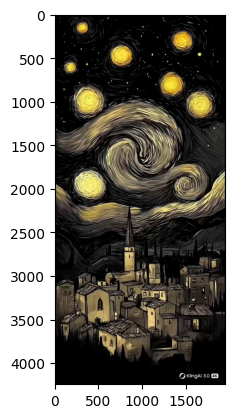

In [ ]:
frames = download_video_data(download_url)

plt.imshow(cv.cvtColor(frames[0], cv.COLOR_BGR2RGB))
plt.show()

# Question 1 (45pts)

1. Extract metadata of the given video, including framerate, duration, resolution, and frame ratio.
2. Resize the given video to the size of `1024x1024`. Display three random frames from the output video.
3. Resize the 1024x1024-video from (2) gradually from `1024x1024` to `512x64`. Display 8 random frames from the output video, and save the video with the name as `[Your student id]_Q13.mp4`.
4. Concatenate the video (3) with its reversed version. Display 8 random frames, and save the video with the name as `[Your student id]_Q14.mp4`.
5. Create a new video by repeating the input video three times in your way. The output video must be smooth in human vision.
Introduce your approach briefly, display 8 random frames, and save the video with the name as `[Your student id]_Q15.mp4`.

In [ ]:
# Q1.1. Extract metadata of the given video, including framerate, duration, resolution, and frame ratio.

height, width = frames[0].shape[:2]
num_frames = len(frames)

video = cv.VideoCapture(download_url)
fps = video.get(cv.CAP_PROP_FPS)
video.release()

duration = num_frames / fps
frame_ratio = width / height

# Display results
print("---- VIDEO METADATA ----")
print(f"Framerate : {fps:.2f} FPS")
print(f"Duration  : {duration:.2f} seconds")
print(f"Resolution: {width} x {height}")
print(f"Frame ratio (W/H): {frame_ratio:.4f}")
print(f"Total frames: {num_frames}")

---- VIDEO METADATA ----
Framerate : 24.00 FPS
Duration  : 3.04 seconds
Resolution: 1952 x 4244
Frame ratio (W/H): 0.4599
Total frames: 73


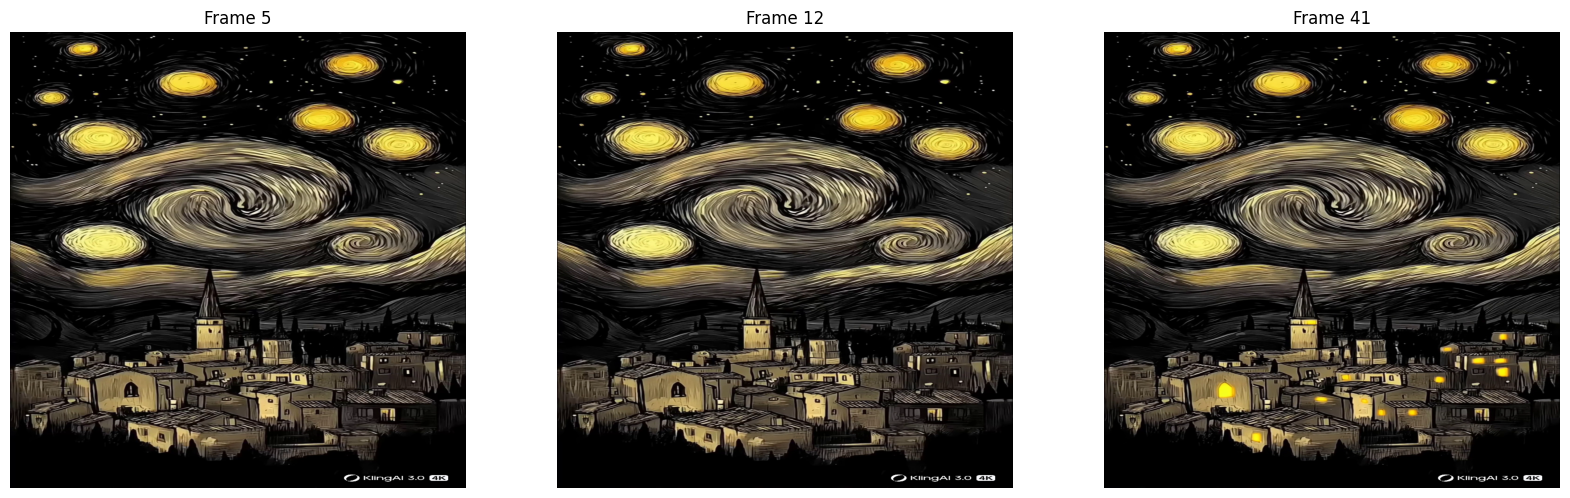

In [ ]:
# Q1.2. Resize the given video to the size of 1024x1024. Display three random frames from the output video.

frames_1024 = [
    cv.resize(frame, (1024, 1024))
    for frame in frames
]

# Display results
idxs = np.random.choice(len(frames_1024), 3, replace=False)

plt.figure(figsize=(20,10))

for i, idx in enumerate(idxs):
    plt.subplot(1,3,i+1)
    plt.imshow(cv.cvtColor(frames_1024[idx], cv.COLOR_BGR2RGB))
    plt.title(f"Frame {idx}")
    plt.axis("off")

plt.show()

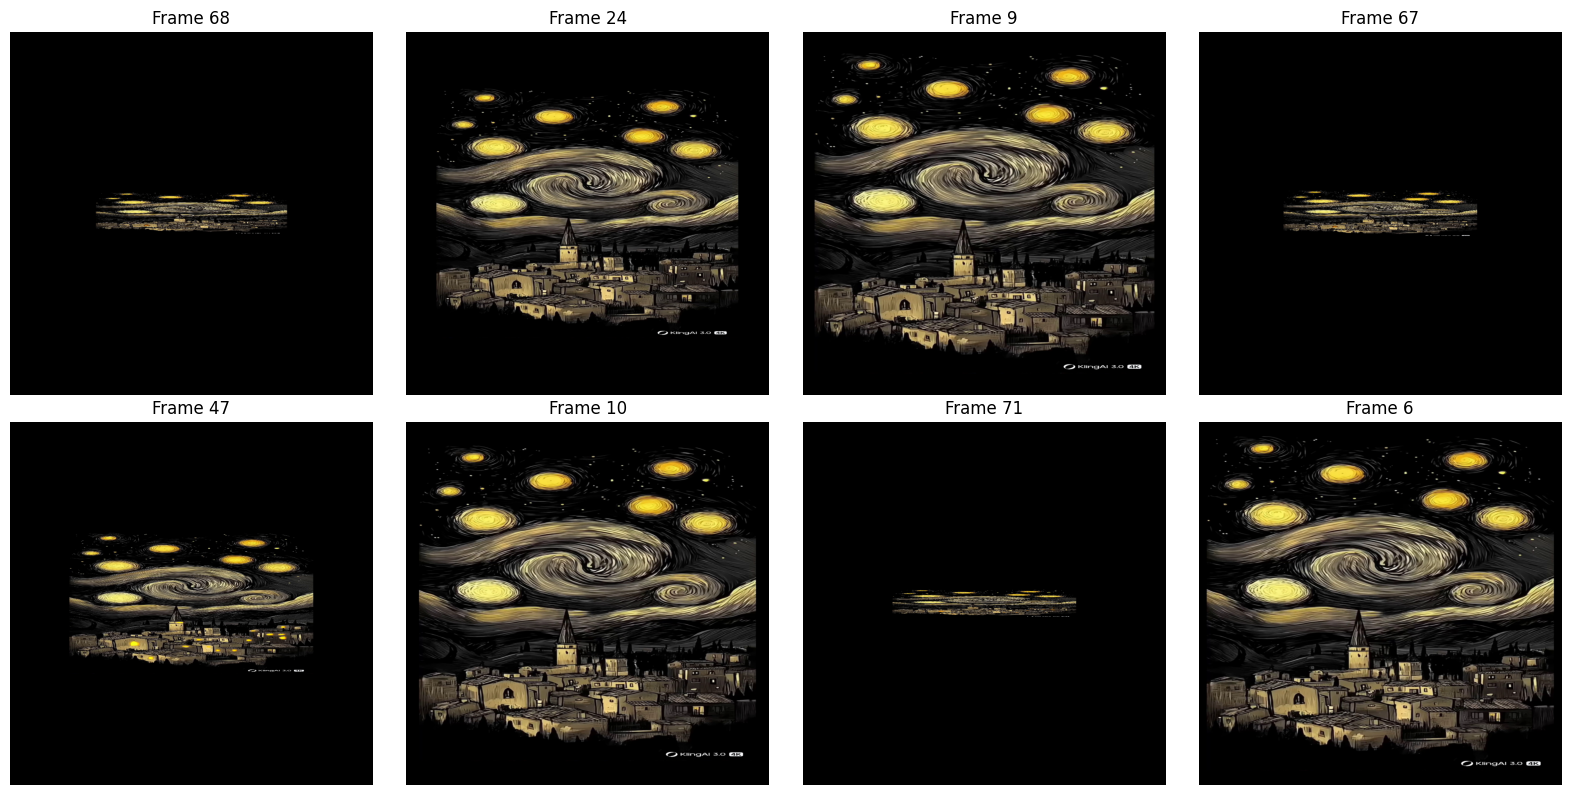

Saved: 25MS33062_Q13.mp4


In [ ]:
# Q1.3. Resize the 1024x1024-video from (2) gradually from 1024x1024 to 512x64. Display 8 random frames from the output video, and save the video with the name as [Your student id]_Q13.mp4.

student_id = "25MS33062"

n_frames = len(frames_1024)
frames_q13 = []

for i, frame in enumerate(frames_1024):
    t = i / (n_frames - 1)

    new_w = int(1024 - t * (1024 - 512))
    new_h = int(1024 - t * (1024 - 64))

    resized = cv.resize(frame, (new_w, new_h))
    canvas = np.zeros((1024, 1024, 3), dtype=np.uint8)

    x_offset = (1024 - new_w) // 2
    y_offset = (1024 - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = resized

    frames_q13.append(canvas)

video = cv.VideoCapture(download_url)
fps = video.get(cv.CAP_PROP_FPS)
video.release()

fourcc = cv.VideoWriter_fourcc(*'mp4v')

writer = cv.VideoWriter(
    f"{student_id}_Q13.mp4",
    fourcc,
    fps,
    (1024, 1024)
)

for frame in frames_q13:
    writer.write(frame)

writer.release()

# Display results
idxs = np.random.choice(len(frames_q13), 8, replace=False)

plt.figure(figsize=(16, 8))

for i, idx in enumerate(idxs):
    plt.subplot(2, 4, i + 1)
    plt.imshow(cv.cvtColor(frames_q13[idx], cv.COLOR_BGR2RGB))
    plt.title(f"Frame {idx}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Saved: {student_id}_Q13.mp4")

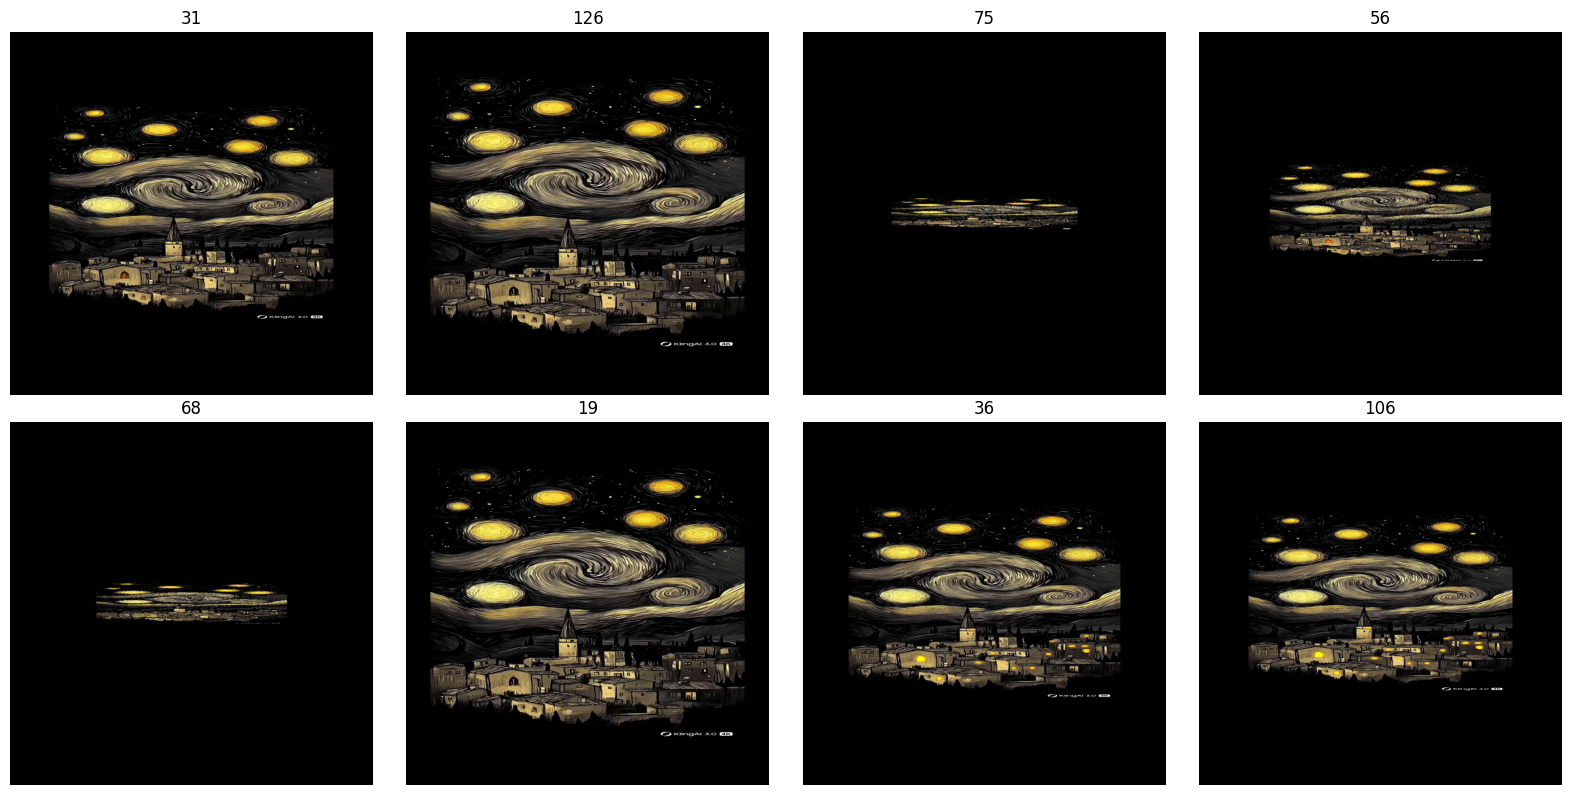

In [ ]:
# Q1.4. Concatenate the video (3) with its reversed version. Display 8 random frames, and save the video with the name as [Your student id]_Q14.mp4.

frames_q14 = frames_q13 + frames_q13[::-1]

writer = cv.VideoWriter(
    f"{student_id}_Q14.mp4",
    fourcc,
    fps,
    (1024,1024)
)

for frame in frames_q14:
    writer.write(frame)

writer.release()

# Display results
idxs = np.random.choice(len(frames_q14), 8, replace=False)

plt.figure(figsize=(16,8))

for i, idx in enumerate(idxs):
    plt.subplot(2,4,i+1)
    plt.imshow(cv.cvtColor(frames_q14[idx], cv.COLOR_BGR2RGB))
    plt.title(idx)
    plt.axis("off")

plt.tight_layout()
plt.show()

VideoWriter opened: True
Saved: 25MS33062_Q15.mp4


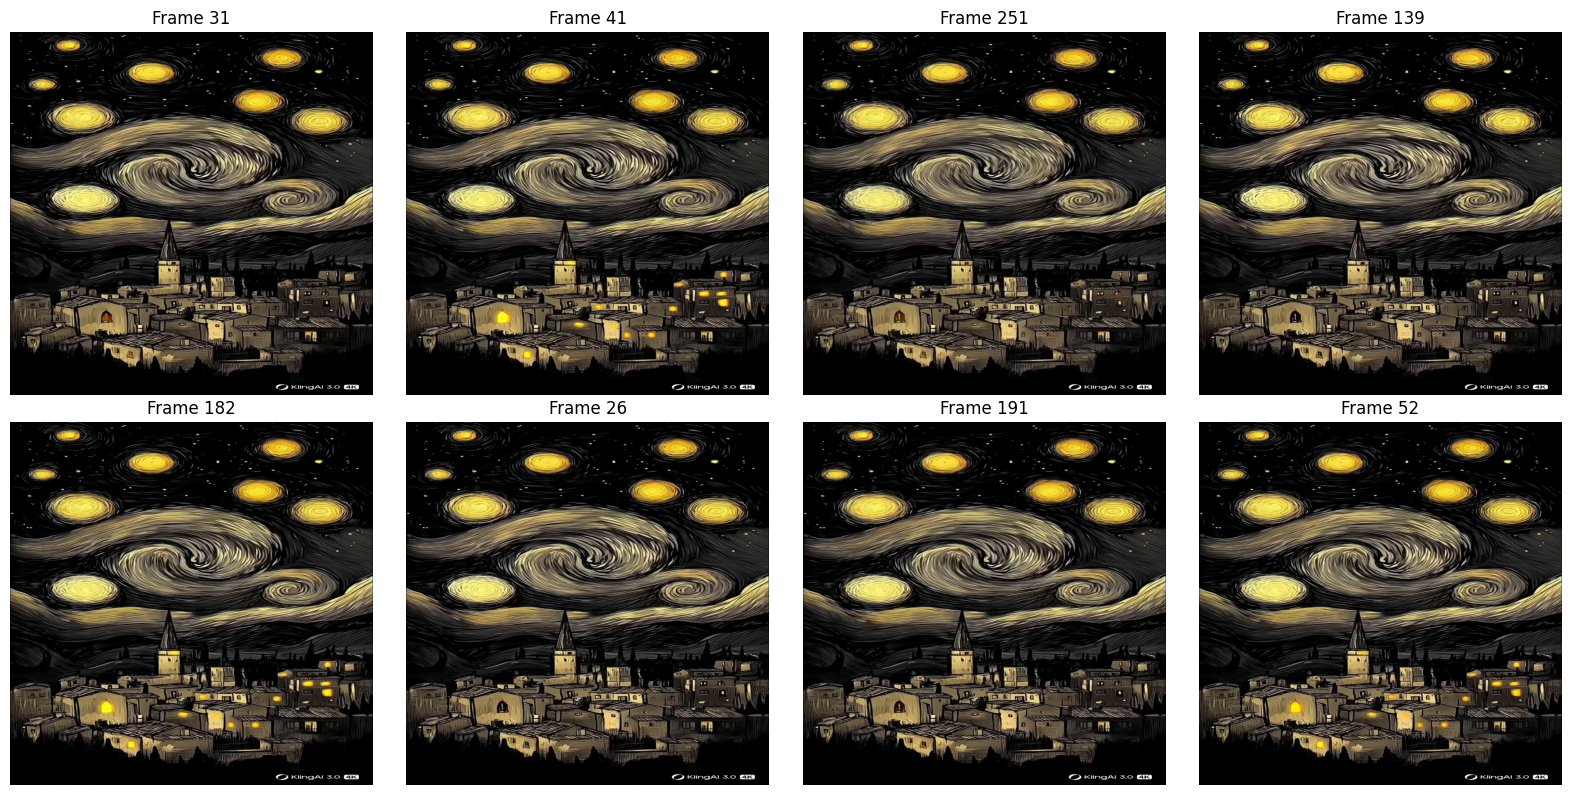

In [ ]:
# Q1.5. Create a new video by repeating the input video three times in your way. The output video must be smooth in human vision. Introduce your approach briefly, display 8 random frames, and save the video with the name as [Your student id]_Q15.mp4.

student_id = "25MS33062"

transition_frames = 60

frames_q15 = []

for repeat in range(3):
    frames_q15.extend(frames)
    if repeat < 2:
        for i in range(transition_frames):
            alpha = (i + 1) / (transition_frames + 1)

            blended = cv.addWeighted(
                frames[-1],
                1 - alpha,
                frames[0],
                alpha,
                0
            )

            frames_q15.append(blended)

frames_q15_resized = [
    cv.resize(frame, (1024, 1024))
    for frame in frames_q15
]

fps = 30

fourcc = cv.VideoWriter_fourcc(*'mp4v')

writer = cv.VideoWriter(
    f"{student_id}_Q15.mp4",
    fourcc,
    fps,
    (1024, 1024)
)

print("VideoWriter opened:", writer.isOpened())

for frame in frames_q15_resized:
    writer.write(frame)

writer.release()

print(f"Saved: {student_id}_Q15.mp4")

# Display results
idxs = np.random.choice(len(frames_q15_resized), 8, replace=False)

plt.figure(figsize=(16, 8))

for i, idx in enumerate(idxs):
    plt.subplot(2, 4, i + 1)
    plt.imshow(cv.cvtColor(frames_q15_resized[idx], cv.COLOR_BGR2RGB))
    plt.title(f"Frame {idx}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Question 2 (25pts)

1. Downscale the given `night_city` video by a half. Print out the metadata of the downscaled video, including framerate, duration, resolution, and frame ratio.
2. Count the amout of moons in the video (2.1) and highlight them by flicker effect. Display 8 random frames and save the output video as `[Your student ID]_Q2.mp4`.

In [ ]:
# Q2.1. Downscale the given night_city video by a half. Print out the metadata of the downscaled video, including framerate, duration, resolution, and frame ratio.

frames_half = []

for frame in frames:
    h, w = frame.shape[:2]
    resized = cv.resize(frame, (w // 2, h // 2))
    frames_half.append(resized)

fps = 30
num_frames = len(frames_half)

h_half, w_half = frames_half[0].shape[:2]

duration = num_frames / fps
frame_ratio = w_half / h_half

# Display results
print("---- DOWNSCALED VIDEO METADATA ----")
print(f"Framerate : {fps:.2f} FPS")
print(f"Duration  : {duration:.2f} seconds")
print(f"Resolution: {w_half} x {h_half}")
print(f"Frame ratio (W/H): {frame_ratio:.4f}")
print(f"Total frames: {num_frames}")

---- DOWNSCALED VIDEO METADATA ----
Framerate : 30.00 FPS
Duration  : 2.43 seconds
Resolution: 976 x 2122
Frame ratio (W/H): 0.4599
Total frames: 73


Number of moons detected: 146
Saved: 25MS33062_Q2.mp4


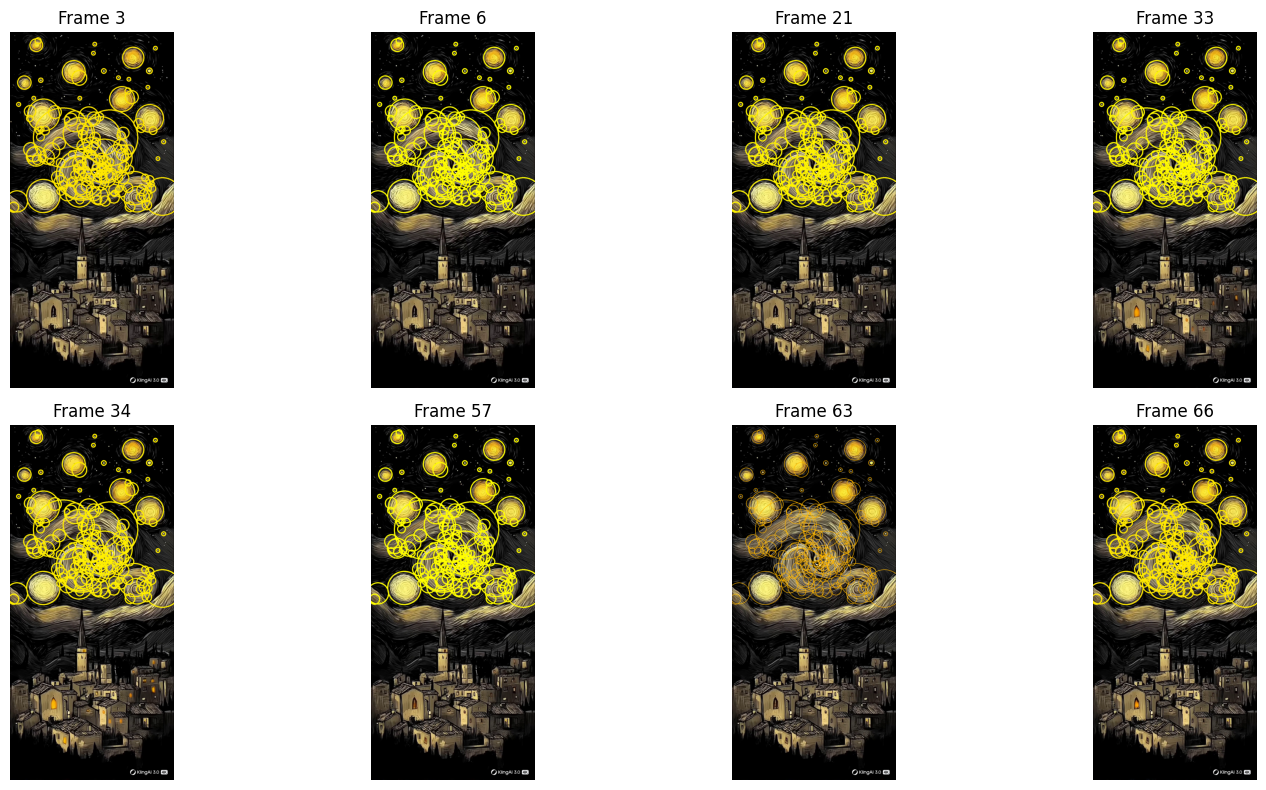

In [ ]:
# Q2.2. Count the amout of moons in the video (2.1) and highlight them by flicker effect. Display 8 random frames and save the output video as [Your student ID]_Q2.mp4.

student_id = "25MS33062"

first_frame = frames_half[0]

H, W = first_frame.shape[:2]

sky = first_frame[:H//2, :]

gray = cv.cvtColor(sky, cv.COLOR_BGR2GRAY)

_, thresh = cv.threshold(
    gray,
    140,
    255,
    cv.THRESH_BINARY
)

kernel = np.ones((3,3), np.uint8)

thresh = cv.morphologyEx(
    thresh,
    cv.MORPH_CLOSE,
    kernel
)

contours, _ = cv.findContours(
    thresh,
    cv.RETR_EXTERNAL,
    cv.CHAIN_APPROX_SIMPLE
)

moons = []

for cnt in contours:
    area = cv.contourArea(cnt)

    if area < 20:
        continue

    (x, y), radius = cv.minEnclosingCircle(cnt)

    if radius < 3:
        continue

    moons.append(
        (
            int(x),
            int(y),
            int(radius)
        )
    )

print("Number of moons detected:", len(moons))

frames_q2 = []

for frame_idx, frame in enumerate(frames_half):

    output = frame.copy()

    pulse = abs(np.sin(frame_idx * 0.25))

    thickness = int(2 + 5 * pulse)

    color = (
        0,
        int(180 + 75 * pulse),
        255
    )

    for x, y, r in moons:

        cv.circle(
            output,
            (x, y),
            r + 8,
            color,
            thickness
        )

    frames_q2.append(output)

fps = 30

h, w = frames_q2[0].shape[:2]

fourcc = cv.VideoWriter_fourcc(*'mp4v')

writer = cv.VideoWriter(
    f"{student_id}_Q2.mp4",
    fourcc,
    fps,
    (w, h)
)

for frame in frames_q2:
    writer.write(frame)

writer.release()

print(f"Saved: {student_id}_Q2.mp4")

# Display results
idxs = np.random.choice(
    len(frames_q2),
    8,
    replace=False
)

plt.figure(figsize=(16,8))

for i, idx in enumerate(sorted(idxs)):

    plt.subplot(2,4,i+1)

    plt.imshow(
        cv.cvtColor(
            frames_q2[idx],
            cv.COLOR_BGR2RGB
        )
    )

    plt.title(f"Frame {idx}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Question 3 (30pts)

Highlight the lighting window in the video (2.1). Display 8 random frames and save the output video as `[Your student ID]_Q3.mp4`. See this [video](https://drive.google.com/file/d/1ZGOs_I4GhMxmuqEtlvIi3rxkCPrJfDXZ/view?usp=share_link) as reference for highlighting effect and output preparation.

Đã lưu video thành công: 25MS33062_Q3.mp4


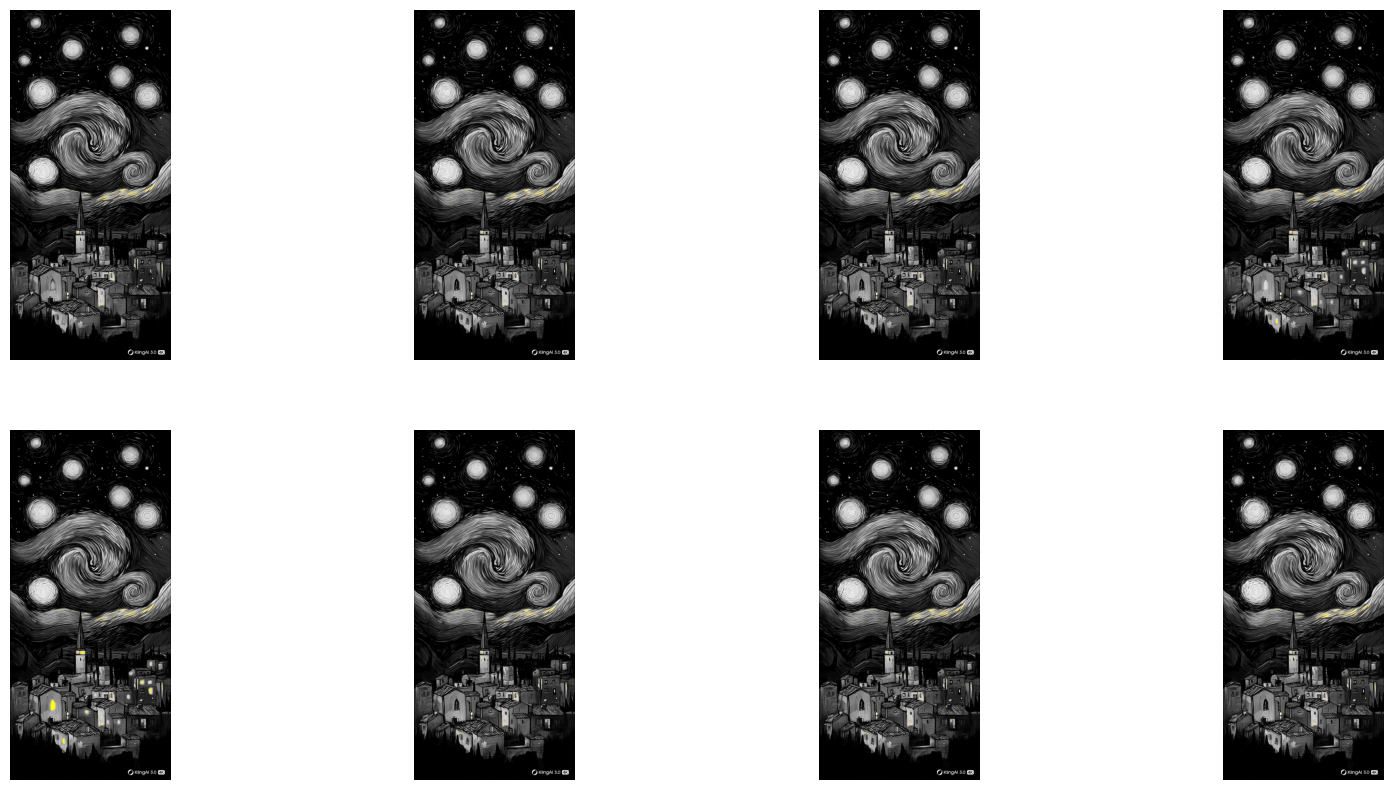

In [ ]:
# Q3. Highlight the lighting window in the video (2.1). Display 8 random frames and save the output video as [Your student ID]_Q3.mp4. See this video as reference for highlighting effect and output preparation.

import cv2 as cv
import numpy as np
import random
import matplotlib.pyplot as plt

out = cv.VideoWriter('25MS33062_Q3.mp4', cv.VideoWriter_fourcc(*'mp4v'), fps, (w_half, h_half))
output_frames = []

for frame in frames_half:
    h, w = frame.shape[:2]
    roi = frame[h//2:h, 0:w]

    gray_full = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    frame_gray = cv.cvtColor(gray_full, cv.COLOR_GRAY2BGR)

    gray_roi = cv.cvtColor(roi, cv.COLOR_BGR2GRAY)
    _, thresh = cv.threshold(gray_roi, 220, 255, cv.THRESH_BINARY)

    kernel = np.ones((5,5), np.uint8)
    thresh = cv.dilate(thresh, kernel, iterations=1)

    mask = np.zeros((h, w), dtype=np.uint8)
    mask[h//2:h, 0:w] = thresh
    mask_bgr = cv.cvtColor(mask, cv.COLOR_GRAY2BGR)

    final_frame = np.where(mask_bgr == 255, frame, frame_gray)

    output_frames.append(final_frame)
    out.write(final_frame)

out.release()
print("Đã lưu video thành công: 25MS33062_Q3.mp4")

# Display results
indices = random.sample(range(len(output_frames)), 8)
plt.figure(figsize=(20, 10))
for i, idx in enumerate(indices):
    plt.subplot(2, 4, i + 1)
    plt.imshow(cv.cvtColor(output_frames[idx], cv.COLOR_BGR2RGB))
    plt.axis('off')
plt.show()